# 13 — Creator × views: quem posta importa?

Em redes reais, o creator costuma ser o fator que mais pesa: cada um tem sua audiência.
Aqui testamos isso de quatro formas:
1. **Identidade:** qual coluna identifica um creator (`creator_id` ou `creator_name`)?
2. **Quanto da variação é do creator?** ICC = % da variação de views, likes e comentários ligada ao creator.
3. **As médias dos creators variam mais que o acaso?** Comparamos com os mesmos posts redistribuídos ao acaso entre creators.
4. **Os melhores continuam os melhores?** Top 10% do 1º ano × 2º ano, e um ranking honesto (média ajustada pelo nº de posts).

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import creators as cr
cr.identity_check(df)

52,214 posts


,valores únicos,posts por valor (mediana),valores com 2+ posts,ids diferentes por nome (máx.),nomes diferentes por id (mediana)
coluna,,,,,
creator_id,5000,10.0000,5000,NaN,10.0000
creator_name,42213,1.0000,6310,19.0000,NaN


**Leitura:** `creator_id` é a única identidade possível (5 mil creators, ~10 posts cada). `creator_name` tem 42 mil valores, e o mesmo nome aparece em vários ids (nomes gerados). Mesmo assim, cada `creator_id` aparece com ~10 nomes e seguidores diferentes, então é um identificador fraco.

## 1. Quanto da variação pertence ao creator?

In [2]:
cr.variance_share(df).round(4)

,creators,F,p_value,ICC (% da variação ligada ao creator)
métrica,,,,
views,5000,0.9985,0.5260,0.0000
likes,5000,1.0068,0.3708,0.0654
comments_count,5000,0.9817,0.8076,0.0000


**Leitura:** ICC ≈ 0% nas três métricas. Saber quem postou não explica nada do resultado.

## 2. As médias dos creators variam mais que o acaso?

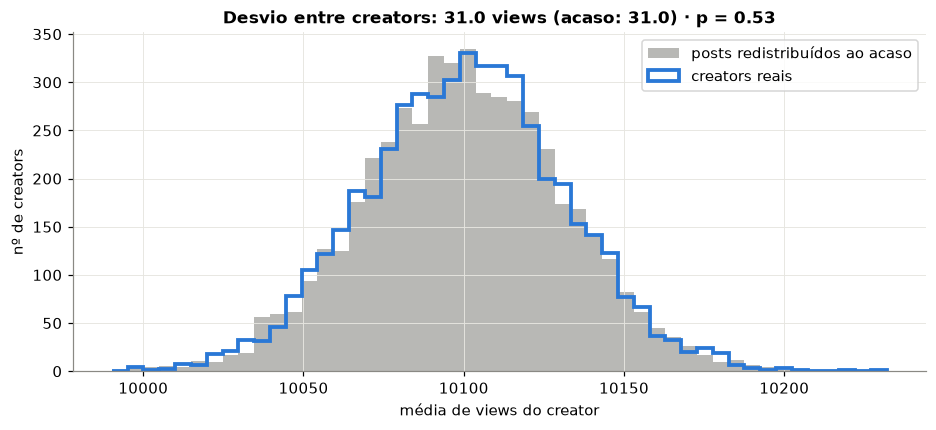

In [3]:
spread = cr.spread_vs_chance(df)
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(min(spread["medias"].min(), spread["medias_acaso"].min()), max(spread["medias"].max(), spread["medias_acaso"].max()), 50)
ax.hist(spread["medias_acaso"], bins=bins, color=plots.GRAY, alpha=0.6, label="posts redistribuídos ao acaso")
ax.hist(spread["medias"], bins=bins, histtype="step", linewidth=2.5, color=plots.BLUE, label="creators reais")
ax.set_xlabel("média de views do creator"); ax.set_ylabel("nº de creators"); ax.legend()
ax.set_title(f"Desvio entre creators: {spread['desvio observado']:.1f} views (acaso: {spread['desvio esperado por acaso']:.1f}) · p = {spread['p_value']:.2f}")
plt.show()

**Leitura:** as duas distribuições se sobrepõem. A diferença entre o "melhor" e o "pior" creator é **exatamente** a que surgiria sorteando os posts entre eles.

## 3. Os melhores continuam os melhores?

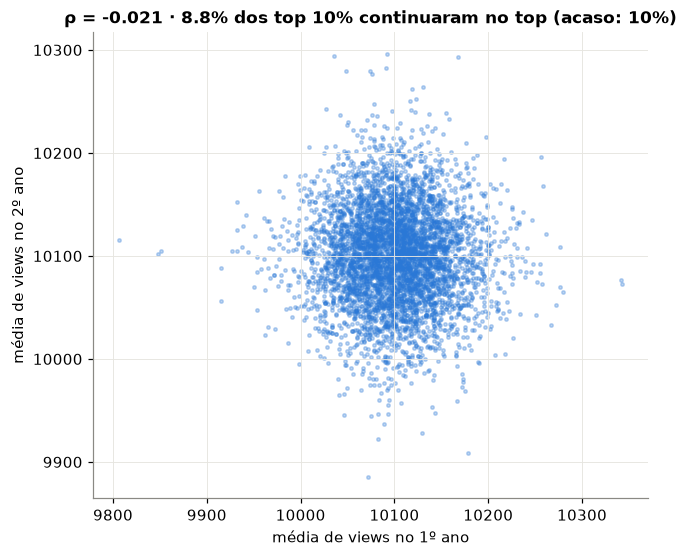

{'creators': 4996,
 'top no 1º ano': 500,
 'continuaram no top': 44,
 '% que continuou': np.float64(8.799999999999999),
 '% esperado por acaso': 10.0,
 'p (continuou acima do acaso)': np.float64(0.8335385274626187),
 'ρ 1º × 2º ano': np.float64(-0.021049649844542363),
 'p_value ρ': np.float64(0.1368479608626629)}

In [4]:
pers = cr.persistence(df)
t = pers["tabela"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(t["1º ano"], t["2º ano"], s=5, alpha=0.3, color=plots.BLUE)
ax.set_xlabel("média de views no 1º ano"); ax.set_ylabel("média de views no 2º ano")
ax.set_title(f"ρ = {pers['ρ 1º × 2º ano']:.3f} · {pers['% que continuou']:.1f}% dos top 10% continuaram no top (acaso: 10%)")
plt.show()
{k: v for k, v in pers.items() if k != "tabela"}

**Leitura:** nuvem redonda, sem diagonal. Dos 500 creators no top 10% do 1º ano, só 44 (8,8%) continuaram no top no 2º, **menos** que os 10% do acaso.

## 4. Ranking honesto: média bruta × média ajustada

,posts,média bruta,média ajustada,peso do histórico (%)
creator_id,,,,
creator_4238,10,10232.0000,10100.3000,0.0000
creator_2405,10,10218.0000,10100.3000,0.0000
creator_3655,10,10206.5000,10100.3000,0.0000
creator_3424,10,10200.3000,10100.3000,0.0000
creator_899,11,10200.2000,10100.3000,0.0000
creator_4494,10,10197.7000,10100.3000,0.0000
creator_832,11,10193.2000,10100.3000,0.0000
creator_199,11,10192.2000,10100.3000,0.0000
creator_4603,10,10191.7000,10100.3000,0.0000


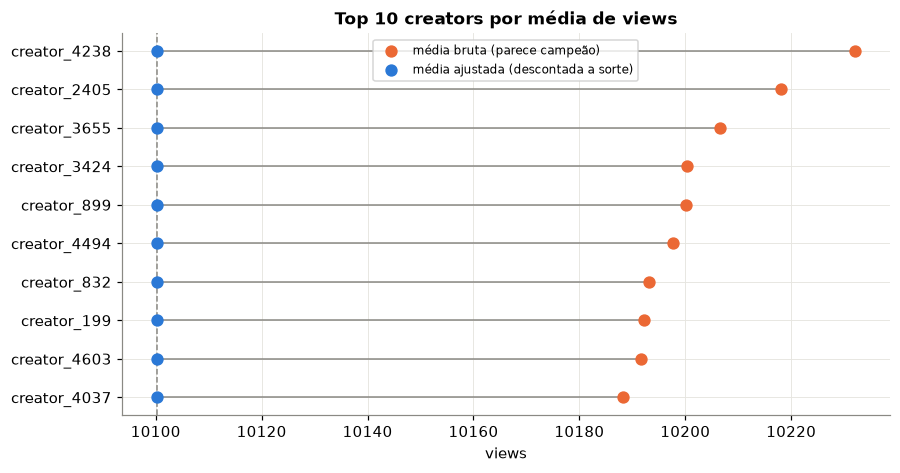

In [5]:
board = cr.leaderboard(df)
display(board.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(board))[::-1]
ax.scatter(board["média bruta"], y, color=plots.ORANGE, s=50, label="média bruta (parece campeão)", zorder=3)
ax.scatter(board["média ajustada"], y, color=plots.BLUE, s=50, label="média ajustada (descontada a sorte)", zorder=3)
for i, (_, r) in zip(y, board.iterrows()):
    ax.plot([r["média ajustada"], r["média bruta"]], [i, i], color=plots.GRAY, linewidth=1)
ax.axvline(df.views.mean(), color=plots.GRAY, linestyle="--", linewidth=1)
ax.set_yticks(y, board.index); ax.set_xlabel("views"); ax.legend(fontsize=8); ax.set_title("Top 10 creators por média de views")
plt.show()

**Leitura:** os "campeões" têm ~10.200 views de média, mas com ~10 posts cada essa vantagem é sorte. Descontada a sorte, todos voltam à média geral (10.100), e o histórico deles tem **peso 0%**.

## 5. Controle positivo
Se cada creator tivesse um nível próprio (±3%), as mesmas funções acusariam: ICC > 50%, médias espalhadas além do acaso e mais de 50% dos top continuando no top (`solution/tests/test_creators.py`).

## Conclusões
1. **Quem posta não importa neste dataset:** 0% da variação de views, likes e comentários está ligada ao creator.
2. **Não há creators campeões:** os rankings por média são sorte e não se repetem de um ano para o outro.
3. **Implicação:** não vale pagar prêmio por um creator por causa do desempenho passado; contratar por preço e por resultado (ver Estratégia).
4. **Com dados reais**, este é provavelmente o primeiro fator a reaparecer, e as mesmas funções medem isso.